# Level Sets – praktické cvičení segmentace obrazu v Pythonu

**Výukový demonstrátor pro studenty informatiky | návaznost na Active Contours a PL09 (Fiji).**

Cíl: porozumět, proč se křivka nemusí ukládat jako seznam jejích bodů. Ukážeme **implicitní funkci** `φ(x,y)`, její **nulovou hladinu** `φ=0`, postupnou evoluci, segmentaci metodou **Chan–Vese** a porovnání s **morfologickou geodetickou aktivní konturou (GAC)**. Na závěr se vrátíme ke dvěma snímkům částic z PL09.

Všechny zde vytvořené snímky jsou syntetické. Ukázky slouží k porozumění algoritmu, nikoli k hodnocení reálných medicínských či průmyslových dat.

**Doporučený postup:** buňky spouštějte postupně. Parametry měňte až po zaznamenání výchozího výsledku.

## 0. Spuštění a knihovny

Z rozbaleného adresáře otevřete terminál a spusťte `python -m pip install -r requirements.txt` a následně `jupyter lab`. Notebook i `level_sets_demo.py` musí zůstat ve stejném adresáři. Nevyžaduje internet pro samotný běh, pokud již máte knihovny nainstalovány.

* NumPy – pole a výpočty; SciPy – vzdálenost, souvislé komponenty;
* scikit-image – úloha Chan–Vese (skutečná evoluce spojité φ) a morfologická GAC (binární aproximace);
* Matplotlib – vizualizace evoluce, masek a energie.

**Pozor:** Morfologická GAC pracuje s binární reprezentací, takže její interní stav není stejná spojitá `φ` jako u klasického Chan–Vese.

In [1]:
from pathlib import Path
from IPython.display import display, Image
import numpy as np
from scipy import ndimage as ndi
import skimage
import level_sets_demo as ls

OUT = Path('vystupy')
OUT.mkdir(exist_ok=True)
print('scikit-image:', skimage.__version__)
print('Složka výstupů:', OUT.resolve())

scikit-image: 0.26.0
Složka výstupů: D:\Dokumenty\Dropbox\UJEP\prog\_MSW2\Data2\vystupy


## 1. Implicitní křivka: co je Level Set?

Místo ukládání posloupnosti bodů křivky definujeme **skalární funkci** $\phi(x,y)$ v každém pixelu. Její **nulová hladina** tvoří hranici:

$$\Gamma(t)=\{(x,y):\phi(x,y,t)=0\},\qquad \text{vnitřek}=\{\phi>0\}. $$

Pro první pokus se křivka pohybuje konstantní rychlostí (bez vazby na obraz):

$$\frac{\partial\phi}{\partial t} + F|\nabla \phi|=0.$$

Tohle je základní demonstrace numerického principu (diskretizovaný výpočet s občasnou reinicializací vzdálenostní funkce), **nikoliv kompletní segmentační algoritmus**. Všimněte si, jak křivka ustupuje a plocha klesá.

Plochy v čase: [(0, 10185), (15, 8321), (30, 6577), (45, 5053), (60, 3685)]


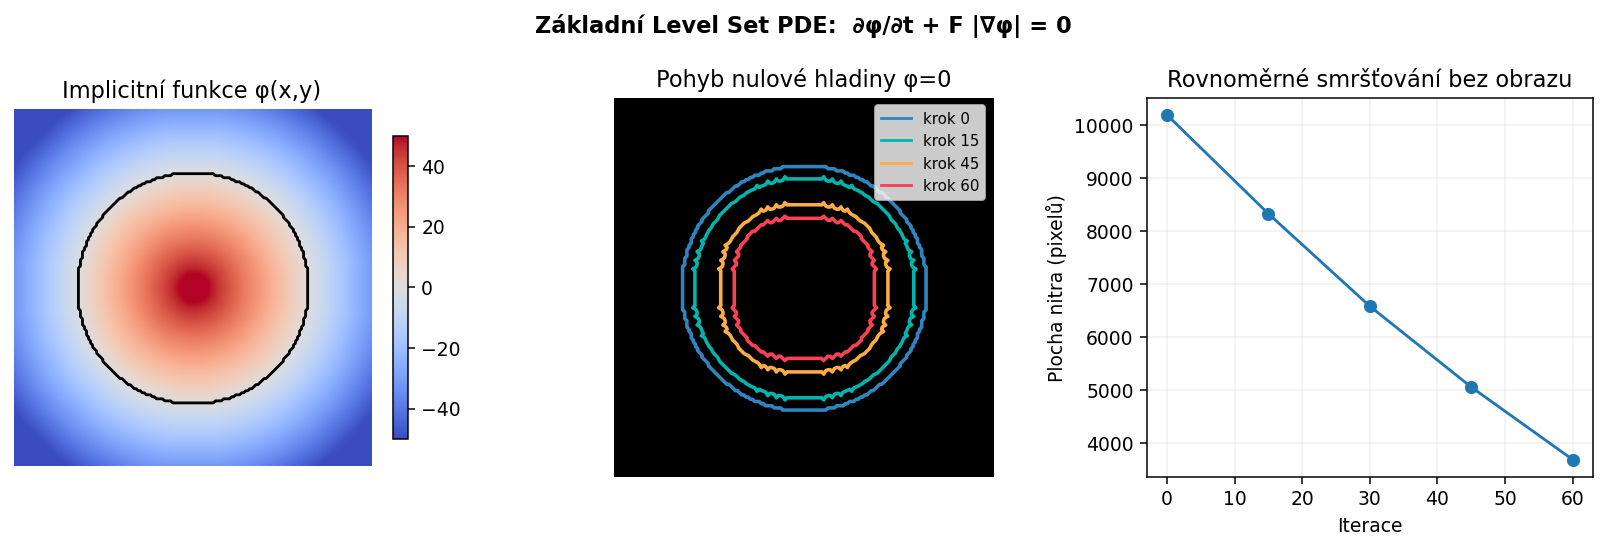

In [8]:
# numerická simulace pohybu nulové hladiny
# shots ... výsledky simulace, dvojice (t, phi), tj. čas a odpovídající hodnoty level set funkce
# steps ... počet kroků
# speed ... rychlost pohybu nulové hladiny (kladné dovnitř)
# dt ...... časový krok
shots = ls.run_normal_flow(steps=60, speed=0.75, dt=0.5)

# výpočet plochy v jednotlivých časových krocích (čas nepotřebujeme)
areas = [int((phi>0).sum()) for _,phi in shots]                 # seznam ploch

# kontrola (plocha na začítku > na konci)
assert areas[0] > areas[-1], 'Při kladné rychlosti se má oblast zmenšovat.'

# výpis ploch v čase (dvojice čas, plocha)
print('Plochy v čase:', list(zip([t for t,_ in shots], areas)))     # seznam časových okamžiků (phi nepotřebujeme) × plochy

#display(shots)
ls._plot_pde(shots, OUT/'00_pohyb_nulove_hladiny.png')              
display(Image(filename=str(OUT/'00_pohyb_nulove_hladiny.png')))

**Otázka:** Co se stane, zvýšíme-li `speed`? Proč se křivka u tohoto experimentu nezastaví na hraně skutečného objektu?

## 2. Chan–Vese: regionově řízené Level Sets

Model minimalizuje kombinaci délky hranice a rozdílu intenzit vně a uvnitř segmentované oblasti (dva typické jasy $c_1$, $c_2$). Zjednodušeně:

$$E = \mu\, \mathrm{Length}(\Gamma) + \lambda_1 \int_{\mathrm{inside}}(I-c_1)^2 \, dx\,dy + \lambda_2 \int_{\mathrm{outside}}(I-c_2)^2\,dx\,dy.$$

* `mu`: vyšší hodnota více penalizuje délku/nerovnost kontury.
* `lambda1`, `lambda2`: váhy shody intenzit v obou regionech.
* `init`: počáteční funkce; zde `checkerboard` dává množství počátečních hranic a dovoluje samovolné slučování nebo rozpad.
* `iterations`: počet kroků; výsledek nemusí být stejně dobrý při všech inicializacích.

Uvidíte nejen hotovou masku, ale i **konečnou spojitou funkci φ** a **průběh energie**.

Ukázka: Dva tmave objekty, lehce zasumeny a pozvolne se menici jas pozadi. Rozměry: (176, 176) Pixelů reference: 5205
Chan–Vese – kvalita: {'IoU': 0.9857954545454546, 'Dice': np.float64(0.9928469241773963)}
Počet komponent (8-sousednost): 2


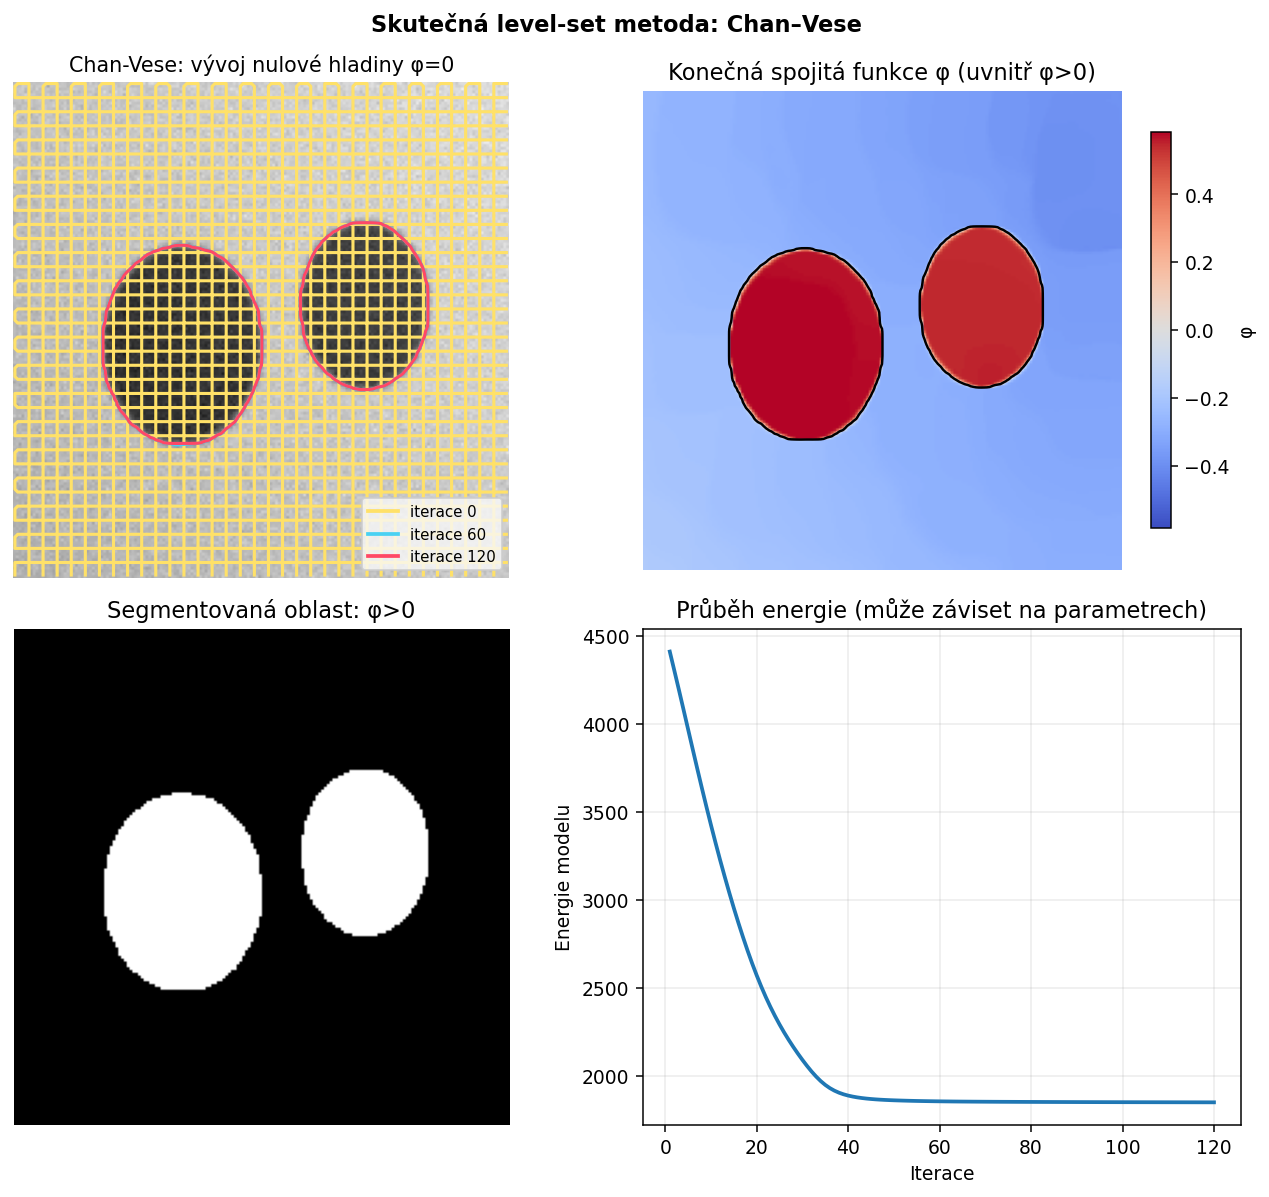

In [ ]:
# vytvoření syntetického obrazu
# image – vstupní obraz, který chceme segmentovat
# truth – referenční maska, která říká, kde se skutečně nacházejí objekty (1 objekt, 0 pozadí)
# description – textový popis vytvořeného obrazu
image, truth, description = ls.make_image('blobs')  
#print(image, truth)    
print('Ukázka:', description, 'Rozměry:', image.shape, 'Pixelů reference:', int(truth.sum()))

# segmentace pomocí metody Chan–Vese
cv = ls.run_chan_vese(image, 
                      init='checkerboard',                  # počáteční rozložení segmentace: šachovnice
                      iterations=120,                       # počet iterací
                      mu=0.25,                              # řídí regularizaci hranice (vyšší hladká a jednoduchá, nižší detailní)
                      dt=0.5,                               # časový krok simulace
                      snapshot_every=20)                    # ukládání průběžných výsledků

# vyhodnocení kvality segmentace
# cv['mask'] – výsledná binární maska vytvořená algoritmem Chan–Vese
# truth – správná referenční maska
score_cv = ls.metrics(cv['mask'], truth)
print('Chan–Vese – kvalita:', score_cv)

print('Počet komponent (8-sousednost):', ndi.label(cv['mask'], np.ones((3,3),int))[1])
assert score_cv['Dice'] > 0.9, 'U tohoto syntetického testu očekáváme dobrou shodu.'
ls._plot_cv(image, cv, OUT/'01_chan_vese.png')
display(Image(filename=str(OUT/'01_chan_vese.png')))

**K čemu je graf energie?** Ukazuje, zda postup vedl k výraznému zlepšování zvoleného kritéria. Ani klesající energie sama o sobě neprokazuje správnost vůči lidské referenci: optimalizujeme model, který může mít nepřesné předpoklady.

## 3. Geodetická aktivní kontura: informace o hranách

Geodetická kontura využívá **edge-stopping function** $g(I)$ – poblíž výrazných obrazových hran má nízké hodnoty. Metoda zde používá **morfologickou aproximaci (MorphGAC)**, která ukládá binární hladinu místo spojité funkce $\phi$.

* `sigma`: měřítko Gaussova vyhlazení při výpočtu hran.
* `balloon`: `-1` konturu přibližně stahuje, `+1` rozšiřuje; znaménko ověřujte proti inicializaci.
* `smoothing`: morfologické vyhlazování křivky.

**Rozdíl:** Chan–Vese se může obejít bez ostře definované hrany, pokud mají oblasti odlišné intenzity. GAC více spoléhá na kvalitu obrazových hran.

MorphGAC – kvalita: {'IoU': 0.9860978861169301, 'Dice': np.float64(0.9930002876594113)}
Počet komponent (8-sousednost): 16


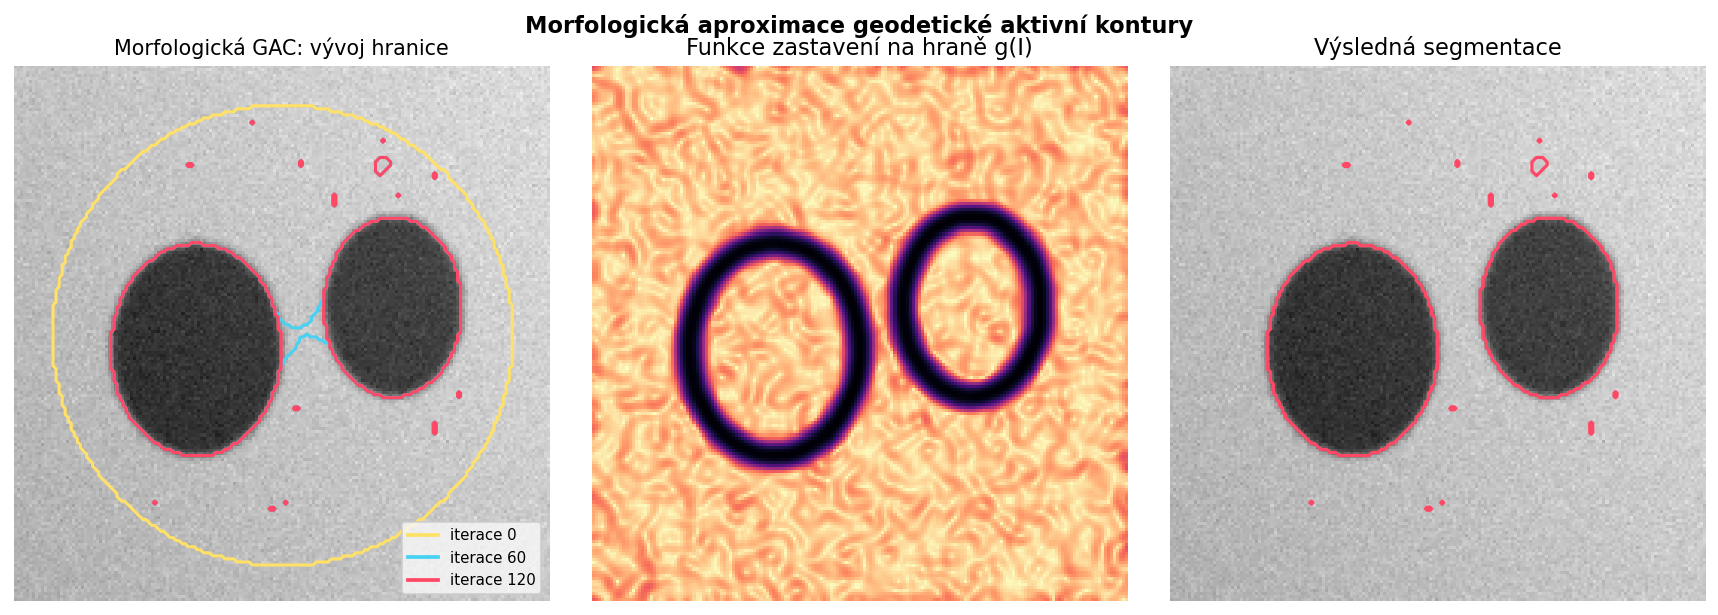

In [4]:
gac = ls.run_gac(image, init='disk', iterations=120,
                 balloon=-1, sigma=2.0, smoothing=1,
                 snapshot_every=20)
score_gac = ls.metrics(gac['mask'], truth)
print('MorphGAC – kvalita:',score_gac)
print('Počet komponent (8-sousednost):',ndi.label(gac['mask'], np.ones((3,3),int))[1])
ls._plot_gac(image, gac, OUT/'02_geodesic_gac.png')
display(Image(filename=str(OUT/'02_geodesic_gac.png')))

**Diskusní otázka:** Proč může Dice vycházet velmi dobře, přestože výsledek obsahuje drobné falešné ostrůvky? Proč pro počítání částic potřebujeme vedle Dice také kontrolu počtu komponent a jednotlivých oblastí?

## 4. Porovnání obou přístupů

Když známe referenční masku, hodnotíme **Dice** nebo **IoU**. U skutečného obrazu taková reference nemusí být dostupná. Důležité je také zobrazit obrys a spočítat samostatné komponenty, nikoliv jen jednu souhrnnou metriku.

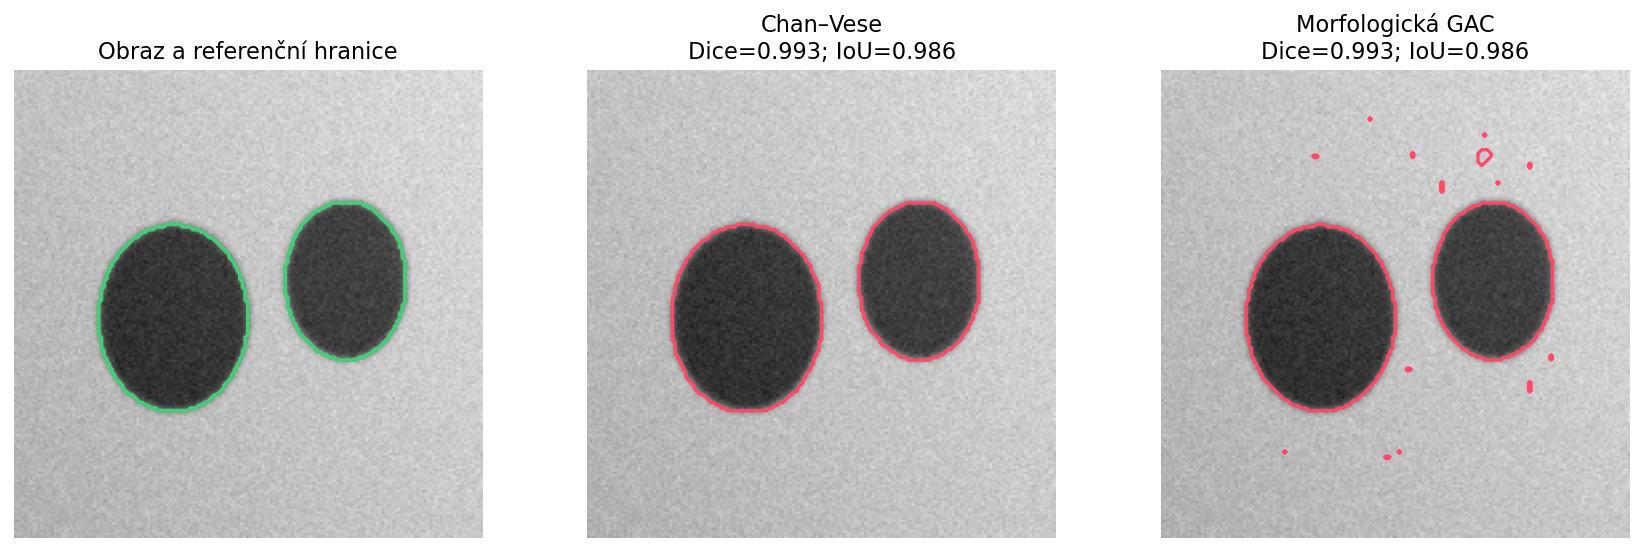

Chan–Vese: Dice=0.993; IoU=0.986; komponenty=2
MorphGAC: Dice=0.993; IoU=0.986; komponenty=16


In [5]:
ls._plot_comparison(image, truth, [cv, gac], OUT/'03_porovnani.png')
display(Image(filename=str(OUT/'03_porovnani.png')))
for label, r in [('Chan–Vese', cv),('MorphGAC',gac)]:
    print(f"{label}: Dice={ls.metrics(r['mask'],truth)['Dice']:.3f}; "
          f"IoU={ls.metrics(r['mask'],truth)['IoU']:.3f}; "
          f"komponenty={ndi.label(r['mask'], np.ones((3,3),int))[1]}")

## 5. Jak záleží na inicializaci a regularizaci?

Provedeme čtyři varianty Chan–Vese. Ve výsledku si všímejte, že **malá počáteční kružnice může vést do jiného lokálního řešení** než mnohočetné počáteční rozhraní. S větším `mu` mívá kontura tendenci být hladší, ale může ztratit drobné detaily.

μ = 0.10; checkerboard          : plocha= 5232, Dice=0.995
μ = 0.45; checkerboard          : plocha= 5356, Dice=0.986
μ = 0.25; malý disk             : plocha= 1680, Dice=0.488
μ = 0.25; checkerboard          : plocha= 5283, Dice=0.993


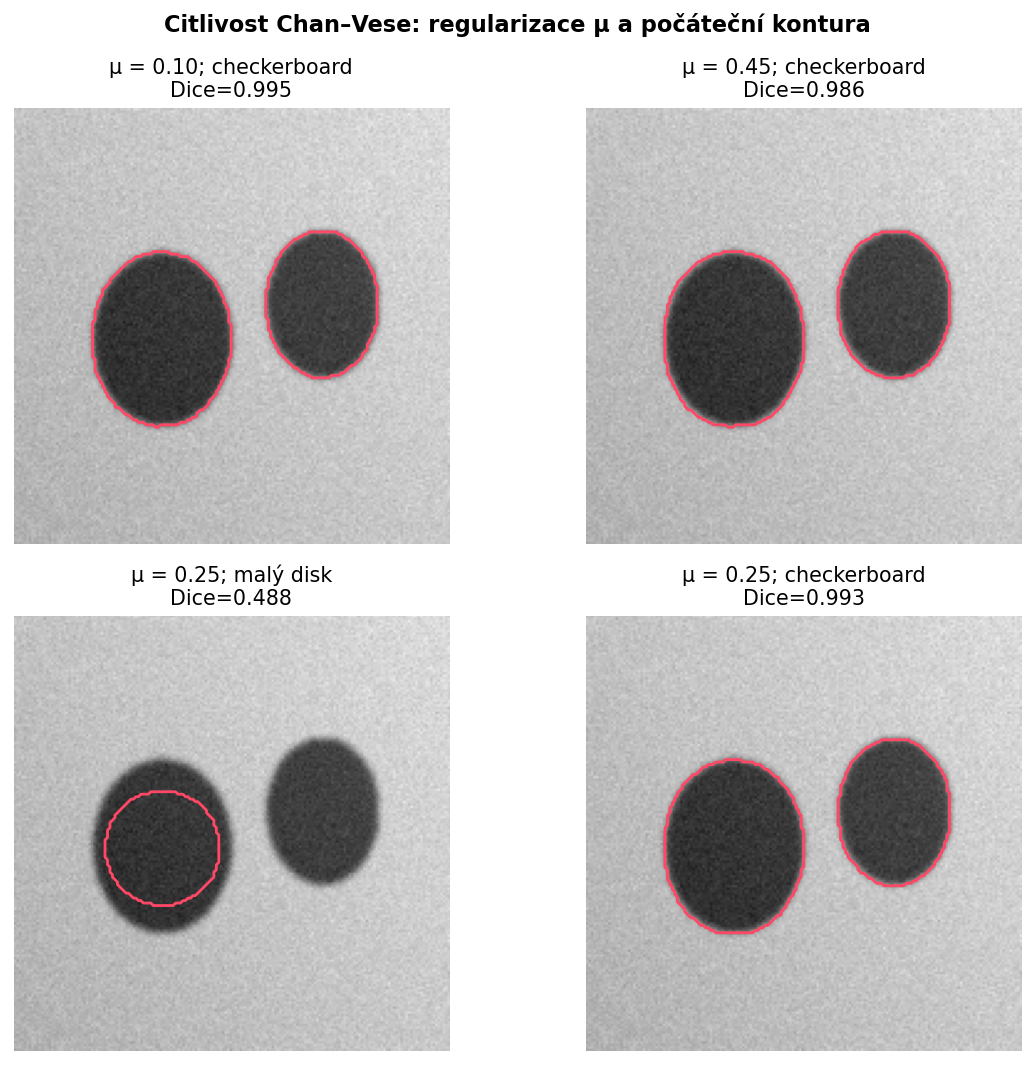

In [6]:
variation = ls.run_experiment(image, truth, OUT/'04_parametry.png', iterations=80)
for title, area, dice in variation:
    print(f'{title:32s}: plocha={area:5d}, Dice={dice:.3f}')
display(Image(filename=str(OUT/'04_parametry.png')))

**Úkol:** Změňte `mu=0.1` na `mu=0.8` u stejné inicializace a iterací, zopakujte výpočet a zapište rozdíl v počtu detekovaných komponent, Dice a podobě hranice.

## 6. Návaznost na PL09 / Fiji – čisté a spojené částice

Použijeme dvě cvičná PNG z předchozího kurzu, ale kvůli rychlosti je analyzujeme **zmenšená na jednu třetinu v obou osách**. Na těchto zmenšených náhledech lze názorně demonstrovat počet komponent. **Výsledné pixelové plochy nejsou fyzikálními plochami původního obrazu; nelze na ně bez úpravy použít původní převod 10 px = 1 mm.**

Cílem je porovnat souvislé oblasti a zamýšlený počet fyzických částic. Ve spojeném obrazu může být 11 souvislých oblastí, přestože vznikl ze 12 původních částic.

fiji-clean : 12 oblastí; referenční očekávání 12 | Dice= 1.0


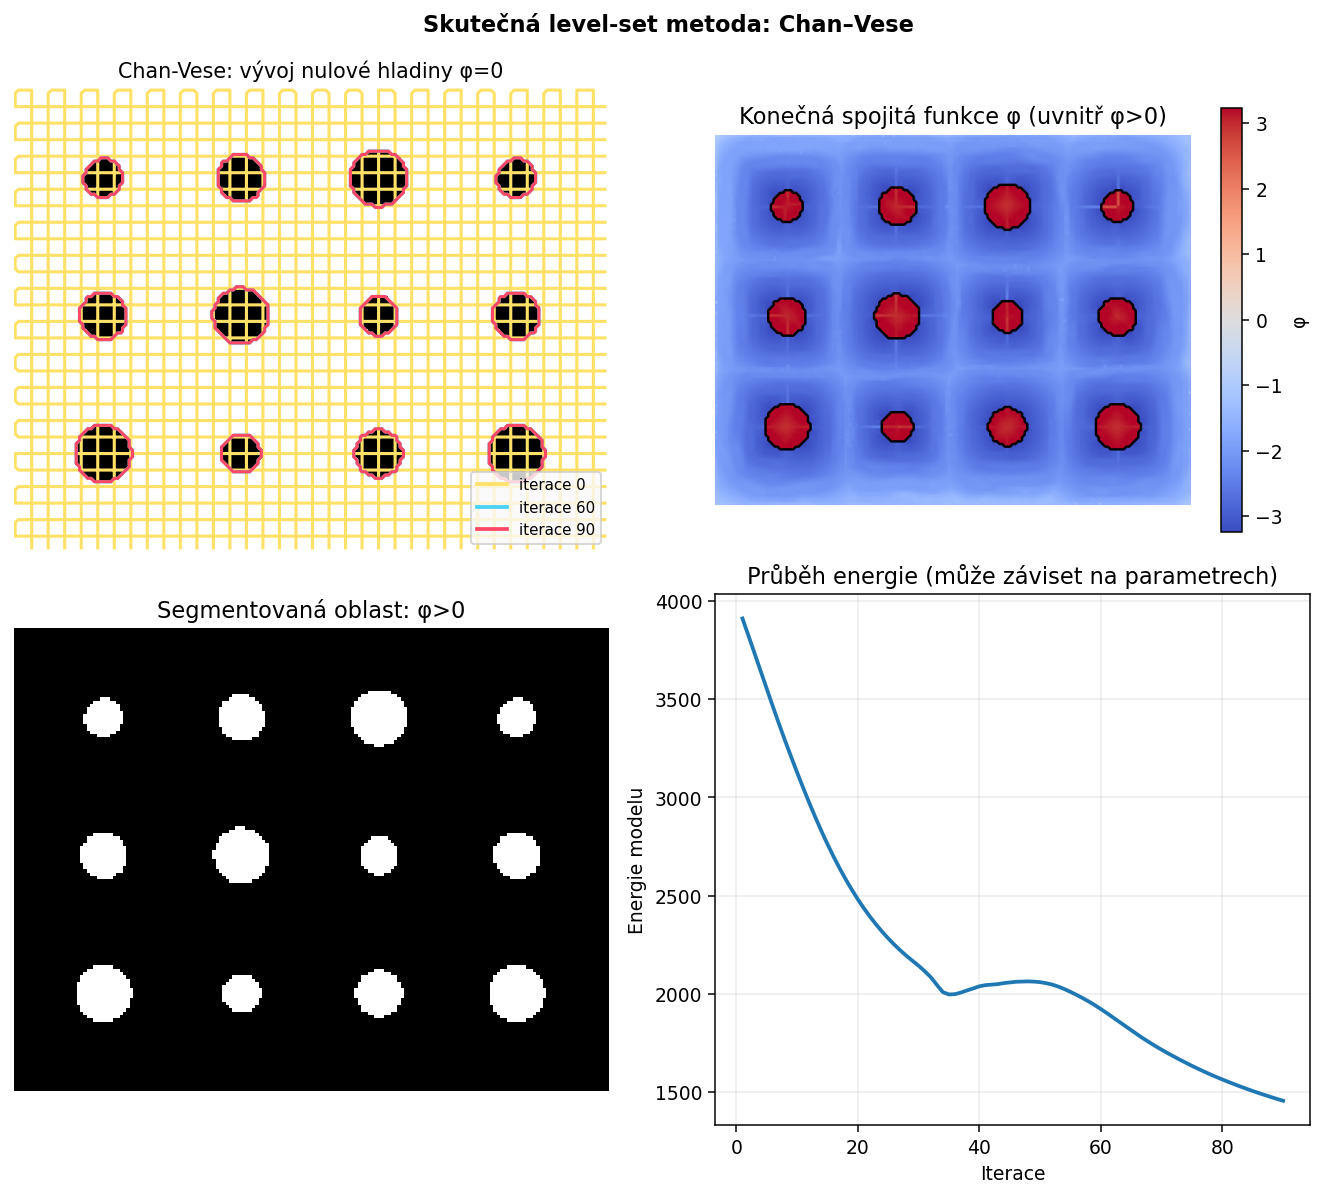

fiji-bridge : 11 oblastí; referenční očekávání 11 | Dice= 1.0


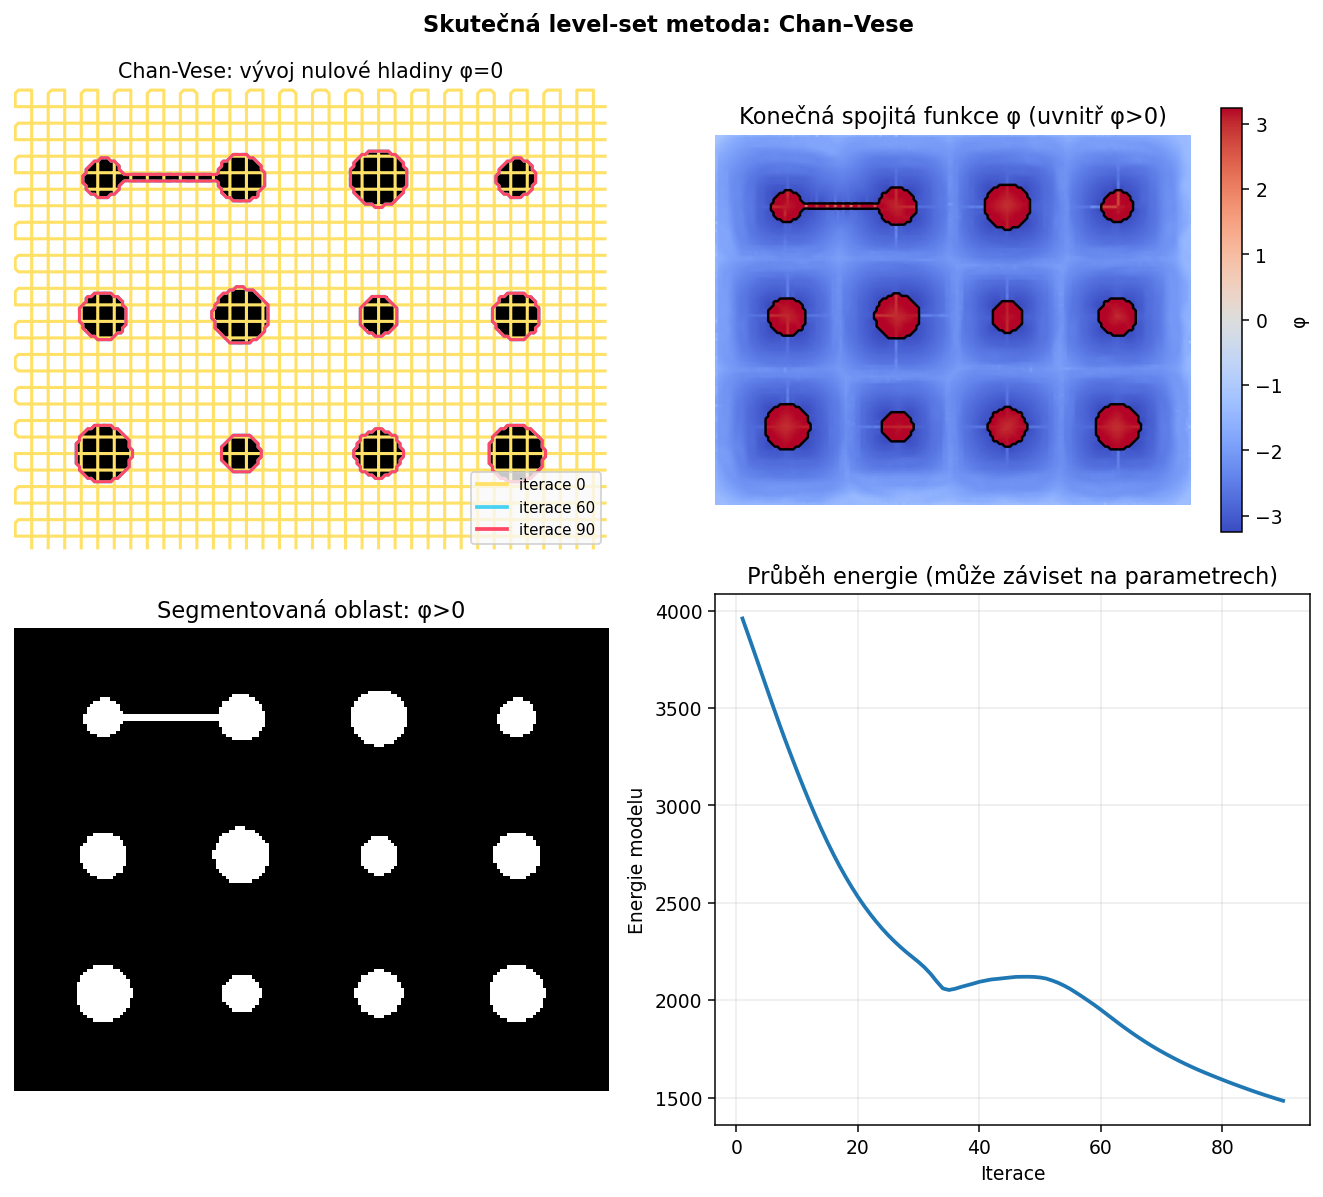

In [7]:
for scenario, expected in [('fiji-clean',12),('fiji-bridge',11)]:
    im, ref, note=ls.make_image(scenario)
    result=ls.run_chan_vese(im, init='checkerboard', iterations=90, snapshot_every=30)
    components=ndi.label(result['mask'], np.ones((3,3),int))[1]
    print(scenario,':',components,'oblastí; referenční očekávání',expected,
          '| Dice=',round(ls.metrics(result['mask'],ref)['Dice'],3))
    assert components==expected
    ls._plot_cv(im,result,OUT/f'05_{scenario}.png')
    display(Image(filename=str(OUT/f'05_{scenario}.png')))

## 7. Náročnější obraz se slabým okrajem

Metoda může mít jinou přesnost na jiných obrazových podmínkách. Podívejte se na jedno těleso s rozmazaným okrajem a nerovnoměrným pozadím. Výsledek nevydávejte za univerzální test algoritmů – jde o **jediný syntetický scénář**.

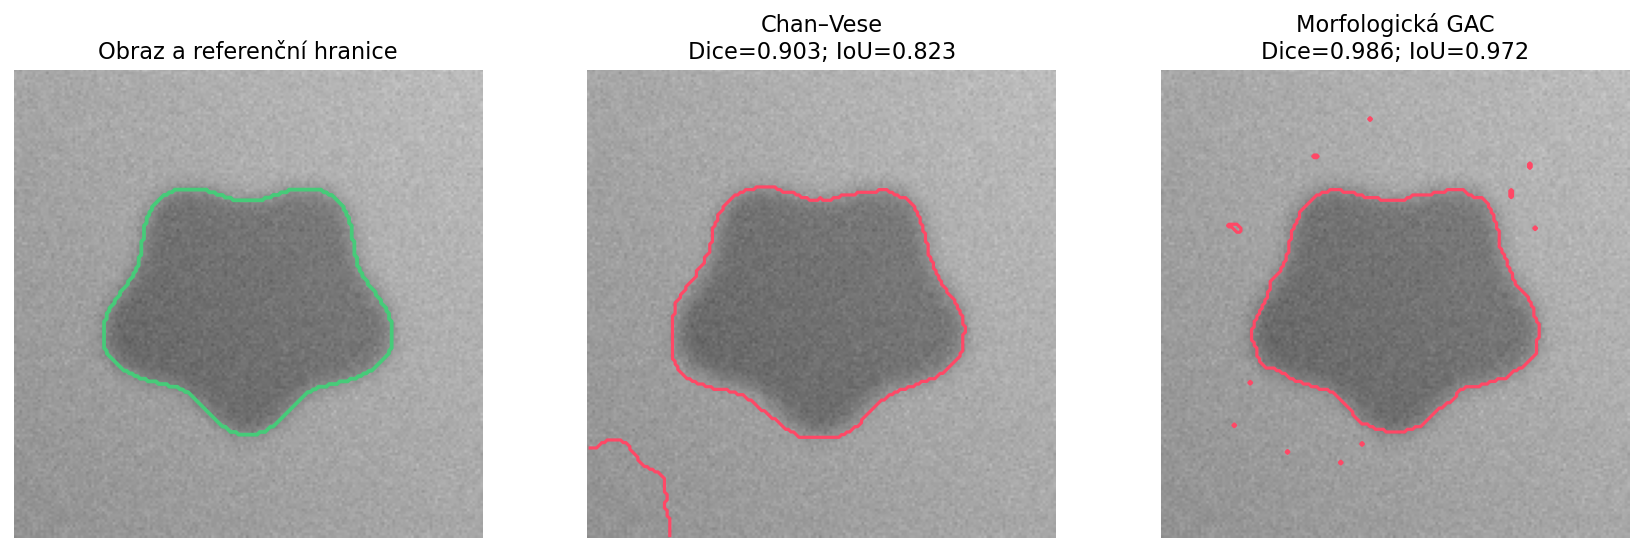

In [8]:
wimg, wgt, _=ls.make_image('weak-edge')
wcv=ls.run_chan_vese(wimg, init='checkerboard', iterations=150, snapshot_every=30)
wgac=ls.run_gac(wimg, init='disk', iterations=150, sigma=2., balloon=-1, smoothing=1)
ls._plot_comparison(wimg,wgt,[wcv,wgac],OUT/'06_slaba_hrana.png')
display(Image(filename=str(OUT/'06_slaba_hrana.png')))

## 8. Samostatné úkoly a vyhodnocení

1. **Inicializace:** Srovnejte `checkerboard` a `small-disk` u dvou objektů. Kolik komponent dostanete? Jak to souvisí s lokálním minimem energie?
2. **Regularizace:** Proveďte `mu=0.10`, `0.25` a `0.8` na stejném obrazu a popište vyhlazení hranic.
3. **Hrany:** V GAC vyzkoušejte `sigma=1.0` a `sigma=4.0`. Jak se mění zastavovací funkce a výsledek?
4. **Snímky Fiji:** Porovnejte 12 zamýšlených fyzických částic s 11 souvislými oblastmi v obrazu s můstkem. Proč samotná topologická flexibilita Level Sets problém nevyřeší bez dalších předpokladů?
5. **Zpráva:** Uveďte vstup, inicializaci, všechna nastavení, snímek před/po, počty oblastí, metriku vůči referenci, a omezení.

**Kontrola před odevzdáním:** V základním obrazu se dvěma objekty je vysoké Dice, ale vždy kontrolujte **počet komponent** a jejich polohu. Není správné tvrdit, že metoda automaticky najde „skutečné“ objekty; segmentuje podle zvoleného modelu.

## Literatura a implementace

- [scikit-image: `chan_vese`, API](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.chan_vese)
- [scikit-image: `morphological_geodesic_active_contour`, API](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.morphological_geodesic_active_contour)
- [Chan–Vese official example](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_chan_vese.html)
- [Morphological snakes official example](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_morphsnakes.html)

**Metodická přesnost:** Chan–Vese využívá evoluci spojité implicitní funkce; morfologická GAC je alternativní aproximace bez přímo uchovávané spojité `φ`. Parametry modelu i inicializace zásadně ovlivňují výsledek. Reálné obrázky vyžadují ověřenou referenci a doménově správnou interpretaci.